In [1]:
#importar librerias
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
class Nodo:
    def __init__(self, valor):
        self.valor = valor
        self.izquierda = None
        self.derecha = None

class ArbolBinario:
    def __init__(self, raiz):
        self.raiz = Nodo(raiz)

    def imprimir_inorden(self, nodo):
        if nodo:
            self.imprimir_inorden(nodo.izquierda)
            print(nodo.valor, end=" ")
            self.imprimir_inorden(nodo.derecha)
            
# Ejemplo de uso
arbol = ArbolBinario(1)
arbol.raiz.izquierda = Nodo(2)
arbol.raiz.derecha = Nodo(3)
arbol.raiz.izquierda.izquierda = Nodo(4)
arbol.raiz.izquierda.derecha = Nodo(5)

print("Recorrido Inorden:")
arbol.imprimir_inorden(arbol.raiz) # Imprime: 4 2 5 1 3

Recorrido Inorden:
4 2 5 1 3 

In [3]:
class Nodo:
    def __init__(self, valor):
        self.valor = valor
        self.izquierda = None
        self.derecha = None

class ArbolBusquedaBinaria:
    def __init__(self, raiz=None):
        self.raiz = raiz

    def insertar(self, valor):
        if self.raiz is None:
            self.raiz = Nodo(valor)
        else:
            self._insertar_recursivo(self.raiz, valor)

    def _insertar_recursivo(self, nodo, valor):
        if valor < nodo.valor:
            if nodo.izquierda is None:
                nodo.izquierda = Nodo(valor)
            else:
                self._insertar_recursivo(nodo.izquierda, valor)
        else:
            if nodo.derecha is None:
                nodo.derecha = Nodo(valor)
            else:
                self._insertar_recursivo(nodo.derecha, valor)

    def buscar(self, valor):
        return self._buscar_recursivo(self.raiz, valor)

    def _buscar_recursivo(self, nodo, valor):
        if nodo is None:
            return False
        if nodo.valor == valor:
            return True
        if valor < nodo.valor:
            return self._buscar_recursivo(nodo.izquierda, valor)
        else:
            return self._buscar_recursivo(nodo.derecha, valor)

# Ejemplo de uso
arbol_bst = ArbolBusquedaBinaria()
arbol_bst.insertar(5)
arbol_bst.insertar(3)
arbol_bst.insertar(7)
arbol_bst.insertar(2)
arbol_bst.insertar(4)

print(arbol_bst.buscar(4))  # Imprime True
print(arbol_bst.buscar(6))  # Imprime False

True
False


In [4]:
grafo = nx.Graph()
grafo.add_nodes_from(["Hugo","Paco","Luis"])

In [5]:
grafo.add_edge("Hugo","Paco",weight=4)
grafo.add_edge("Hugo","Luis",weight=10)
grafo.add_edge("Paco","Luis",weight=2)


In [8]:
#numero de vertices
print("número vértices: ",grafo.number_of_edges())
print("nodos: ",grafo.nodes)

número vértices:  3
nodos:  ['Hugo', 'Paco', 'Luis']


In [6]:
#lista de aristas
print("Aristas: ", grafo.edges)

Aristas:  [('Hugo', 'Paco'), ('Hugo', 'Luis'), ('Paco', 'Luis')]


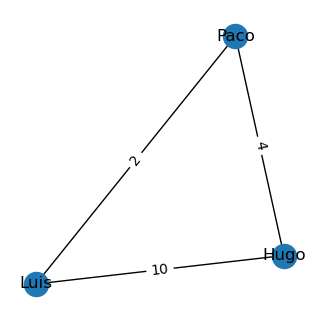

In [8]:
#visualizacion de grafo
plt.figure(figsize=(3,3))
posiciones = nx.spring_layout(grafo,seed=10)
pesos = nx.get_edge_attributes(grafo,"weight")
nx.draw(grafo, posiciones, with_labels=True)
nx.draw_networkx_edge_labels(grafo,posiciones,edge_labels=pesos)
plt.show()

In [10]:
from collections import deque

def bfs(graph, start_node):
    """
    Realiza una búsqueda por amplitud (BFS) en un grafo.

    Args:
        graph (dict): Un diccionario que representa el grafo usando listas de adyacencia.
                      Las claves son los nodos y los valores son listas de sus vecinos.
        start_node: El nodo desde donde comenzar la búsqueda.

    Returns:
        set: Un conjunto de todos los nodos visitados durante la búsqueda.
    """
    visited = set()
    queue = deque([start_node])
    visited.add(start_node)

    while queue:
        current_node = queue.popleft()
        print(f"Visitando nodo: {current_node}")

        for neighbor in graph.get(current_node, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)
    return visited

def dfs(graph, start_node, visited=None):
    """
    Realiza una búsqueda en profundidad (DFS) en un grafo.

    Args:
        graph (dict): Un diccionario que representa el grafo usando listas de adyacencia.
                      Las claves son los nodos y los valores son listas de sus vecinos.
        start_node: El nodo desde donde comenzar la búsqueda.
        visited (set, opcional): Un conjunto para llevar un registro de los nodos visitados.
                                  Se inicializa como un conjunto vacío si no se proporciona.

    Returns:
        set: Un conjunto de todos los nodos visitados durante la búsqueda.
    """
    if visited is None:
        visited = set()
    visited.add(start_node)
    print(f"Visitando nodo: {start_node}")
    for neighbor in graph.get(start_node, []):
        if neighbor not in visited:
            dfs(graph, neighbor, visited)
    return visited

# Ejemplo de grafo representado con listas de adyacencia
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['F'],
    'F': []
}

print("BFS:")
visited_bfs = bfs(graph, 'A')
print(f"Nodos visitado+s (BFS): {visited_bfs}\n")

print("DFS:")
visited_dfs = dfs(graph, 'A')
print(f"Nodos visitados (DFS): {visited_dfs}")

BFS:
Visitando nodo: A
Visitando nodo: B
Visitando nodo: C
Visitando nodo: D
Visitando nodo: E
Visitando nodo: F
Nodos visitados (BFS): {'C', 'D', 'A', 'B', 'F', 'E'}

DFS:
Visitando nodo: A
Visitando nodo: B
Visitando nodo: D
Visitando nodo: E
Visitando nodo: F
Visitando nodo: C
Nodos visitados (DFS): {'D', 'C', 'A', 'B', 'F', 'E'}
